# 🔥 Детектор горячих юпитеров

**Бинарная классификация экзопланет: горячий юпитер / не горячий юпитер**

Логистическая регрессия по звёздным, орбитальным признакам и методу открытия.

---

## 📋 О проекте

Горячие юпитеры — газовые гиганты с массой/радиусом порядка юпитерианских,
но с крайне коротким периодом обращения (P < 10 суток) и высокой равновесной
температурой (T_eq > 1000 K). Это редкий, но физически важный класс планет:
их существование на таких орбитах требует миграции из внешних областей
протопланетного диска.

**Цель:** построить модель логистической регрессии, которая по доступным
характеристикам (свойства звезды, орбитальные параметры, метод открытия)
предсказывает, является ли экзопланета горячим юпитером.

**Данные:** NASA Exoplanet Archive — таблица Confirmed Planets.

**Стек:** Python, pandas, numpy, scikit-learn, matplotlib, seaborn, joblib, imbalanced-learn.

**Воспроизводимость:** `random_state = 42` фиксируется во всех экспериментах.

## 🎯 Постановка задачи

**Тип задачи:** бинарная классификация (обучение с учителем).

**Целевая переменная `is_hot_jupiter`:**

    is_hot_jupiter = 1, если pl_orbper < 10 суток И pl_rade > 8 R⊕
                   = 0, иначе

Порог по радиусу (8 R⊕) отделяет газовых гигантов от нептунов и
суперземель; порог по периоду (10 суток) — классическое определение
горячего юпитера в литературе.

**Важно (защита от утечки):** признаки `pl_orbper` и `pl_rade` входят
в определение таргета, поэтому **исключаются из набора фич**. Модель
учится предсказывать класс только по косвенным признакам:
свойствам звезды, орбитальным параметрам (полуось, эксцентриситет,
инсоляция) и методу открытия. Это честная постановка — иначе модель
выучила бы тривиальное правило `pl_orbper<10 & pl_rade>8`.

**Метрики:** accuracy, precision, recall, F1, ROC-AUC, PR-AUC.
Основной ориентир — **F1 и PR-AUC**, так как классы сильно
несбалансированы (горячих юпитеров ~5–10% выборки).

## 🗄 Описание данных

**Источник:** NASA Exoplanet Archive, таблица *Confirmed Planets*
(https://exoplanetarchive.ipac.caltech.edu/).

**Объём:** ~40 000 записей, ~90 колонок (на момент выгрузки).
Реальная выборка после фильтрации — см. вывод ниже.

**Ключевые колонки, которые используются в проекте:**

| Колонка | Описание | Роль |
|---|---|---|
| `pl_orbper` | орбитальный период, сут | **только для определения таргета** |
| `pl_rade` | радиус планеты, R⊕ | **только для определения таргета** |
| `pl_bmasse` | масса планеты, M⊕ | фича (+ индикатор пропуска) |
| `pl_orbsmax` | большая полуось, а.е. | фича (log) |
| `pl_orbeccen` | эксцентриситет | фича |
| `pl_insol` | инсоляция, S⊕ | фича (log) |
| `st_teff` | эффективная температура звезды, K | фича |
| `st_rad` | радиус звезды, R☉ | фича (log) |
| `st_mass` | масса звезды, M☉ | фича (log) |
| `st_met` | металличность [Fe/H] | фича |
| `st_age` | возраст звезды, млрд лет | фича |
| `sy_dist` | расстояние до системы, пк | фича (log) |
| `sy_pnum` | число планет в системе | фича |
| `sy_snum` | число звёзд в системе | фича |
| `discoverymethod` | метод открытия | one-hot |
| `disc_year` | год открытия | фича |

**Известные проблемы данных (ожидаемые):**
- Сильная несбалансированность классов (горячие юпитеры — меньшинство).
- Большое количество пропусков в `pl_bmasse`, `pl_orbeccen`,
  `pl_insol`, `st_age` — типично для архива (RV-массы есть не у всех).
- Категориальный `discoverymethod` требует one-hot-кодирования.
- Положительные величины с тяжёлыми хвостами (`st_rad`, `pl_orbsmax`,
  `sy_dist`) → логарифмирование.

## Подключение и настройка библиотек

In [1]:
# Импорт библиотек
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, auc,
    ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# Проверка версий (для requirements.txt)
import sklearn
print('numpy:', np.__version__)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('matplotlib:', plt.matplotlib.__version__)
print('seaborn:', sns.__version__)

# Фиксация random_state для воспроизводимости
RANDOM_STATE = 42

# Константы задачи
DATA_PATH = '../data/exoplanets.csv'
TARGET = 'is_hot_jupiter'

# Пороги определения горячего юпитера
P_MAX_DAYS   = 10.0    # сут
R_MIN_RADII  = 8.0     # R⊕

numpy: 2.1.3
pandas: 2.2.3
scikit-learn: 1.9.1
matplotlib: 3.10.1
seaborn: 0.13.2


In [2]:
# Фиксация версий пакетов для воспроизводимости
requirements = f"""numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
matplotlib=={plt.matplotlib.__version__}
seaborn=={sns.__version__}
joblib=={joblib.__version__}
"""
with open('requirements.txt', 'w') as f:
    f.write(requirements)
print(requirements)

numpy==2.1.3
pandas==2.2.3
scikit-learn==1.9.1
matplotlib==3.10.1
seaborn==0.13.2
joblib==1.4.2



## Этап 1. Загрузка данных

In [3]:
df = pd.read_csv(DATA_PATH, comment='#', low_memory=False)
print('Размер датасета:', df.shape)
df.head(3)

Размер датасета: (40350, 92)


,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,11 Com b,11 Com,1,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2023-09-19,2023-12,2023-09-19
1,11 Com b,11 Com,0,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-07-23,2011-08,2014-07-23
2,11 Com b,11 Com,0,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-05-14,2008-01,2014-05-14


In [4]:
# компактный обзор
df.info(verbose=False, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40350 entries, 0 to 40349
Columns: 92 entries, pl_name to releasedate
dtypes: float64(71), int64(5), object(16)
memory usage: 28.3+ MB


In [5]:
# сколько записей реально пригодны для задачи
n_total = len(df)
has_orbper = df['pl_orbper'].notna().sum()
has_rade   = df['pl_rade'].notna().sum()
has_both   = (df['pl_orbper'].notna() & df['pl_rade'].notna()).sum()

print(f'Всего записей:                       {n_total}')
print(f'Есть pl_orbper:                      {has_orbper}')
print(f'Есть pl_rade:                        {has_rade}')
print(f'Есть и pl_orbper, и pl_rade:         {has_both}')

Всего записей:                       40350
Есть pl_orbper:                      36919
Есть pl_rade:                        27827
Есть и pl_orbper, и pl_rade:         25507


### Выводы

Среда подготовлена: зафиксированы версии библиотек в `requirements.txt` для воспроизводимости результатов. Зафиксирован `RANDOM_STATE = 42`.

Данные успешно загружены из CSV-файла NASA Exoplanet Archive (таблица *Confirmed Planets*): **40 350 строк × 92 колонки**. 

При загрузке использовался параметр `comment='#'`, так как официальная выгрузка архива содержит блок текстовых метаданных (описание колонок, литература) в начале файла, предварённый символом `#`. 

В данных присутствуют дубликаты по `pl_name` (одна и та же планета может быть описана в нескольких публикациях). На этапе предобработки потребуется дедупликация — оставим только канонические записи, помеченные флагом `default_flag = 1`.

## Этап 2. Первичный анализ данных

In [6]:
# 1. Отбираем только те планеты, где есть и период, и радиус
df_model = df[df['pl_orbper'].notna() & df['pl_rade'].notna()].copy()
print(f'Записей с определимым таргетом (до дедупликации): {len(df_model)}')

# 2. Дедупликация: одна планета = одна строка (оставляем каноническую запись default_flag=1)
df_model = df_model[df_model['default_flag'] == 1].copy()
print(f'Записей после дедупликации: {len(df_model)}')

# 3. Создаем таргет
df_model[TARGET] = (
    (df_model['pl_orbper'] <  P_MAX_DAYS) &
    (df_model['pl_rade']   >  R_MIN_RADII)
).astype(int)

# 4. Смотрим, сколько получилось "горячих юпитеров", а сколько - нет
print('\nРаспределение классов (кол-во):')
print(df_model[TARGET].value_counts().rename(index={0: 'не горячий юпитер', 1: 'горячий юпитер'}))
print('\nРаспределение классов (доли):')
print(df_model[TARGET].value_counts(normalize=True).round(4).rename(index={0: 'не горячий юпитер', 1: 'горячий юпитер'}))

Записей с определимым таргетом (до дедупликации): 25507
Записей после дедупликации: 4788

Распределение классов (кол-во):
is_hot_jupiter
не горячий юпитер    4090
горячий юпитер        698
Name: count, dtype: int64

Распределение классов (доли):
is_hot_jupiter
не горячий юпитер    0.8542
горячий юпитер       0.1458
Name: proportion, dtype: float64


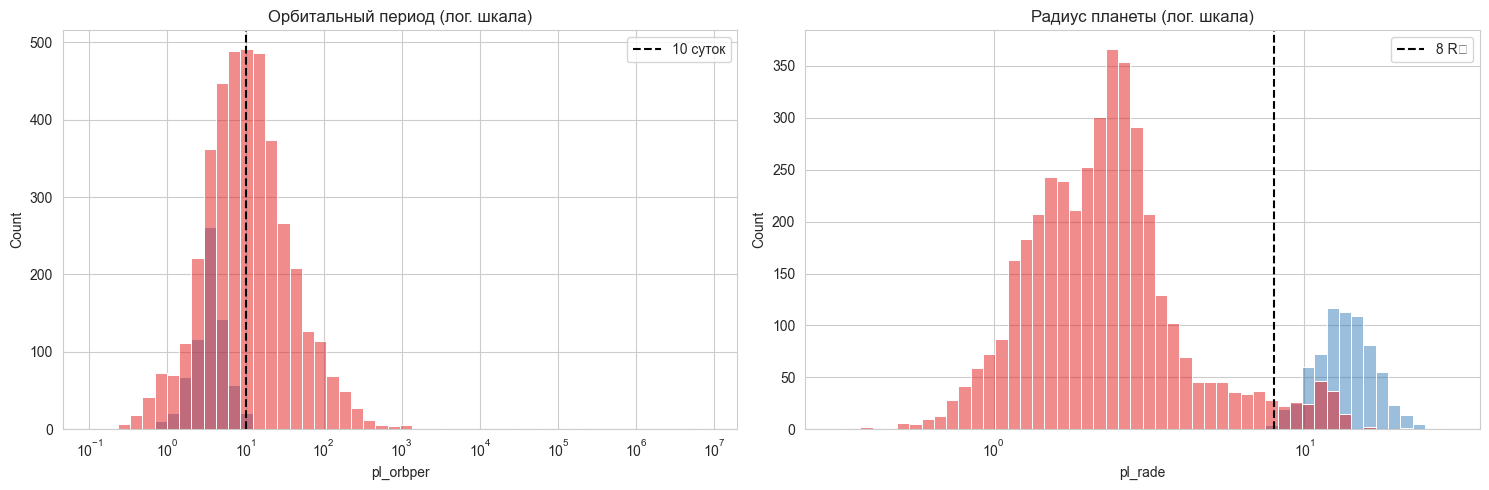

In [7]:
# Визуализация
# Настраиваем сетку графиков
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Распределение периода (лог. шкала) с границей в 10 суток
sns.histplot(data=df_model, x='pl_orbper', hue=TARGET, bins=50, log_scale=True, ax=axes[0], palette='Set1')
axes[0].axvline(P_MAX_DAYS, color='black', linestyle='--', label='10 суток')
axes[0].set_title('Орбитальный период (лог. шкала)')
axes[0].legend()

# 2. Распределение радиуса (лог. шкала) с границей в 8 R⊕
sns.histplot(data=df_model, x='pl_rade', hue=TARGET, bins=50, log_scale=True, ax=axes[1], palette='Set1')
axes[1].axvline(R_MIN_RADII, color='black', linestyle='--', label='8 R⊕')
axes[1].set_title('Радиус планеты (лог. шкала)')
axes[1].legend()

plt.tight_layout()
plt.show()

### Вывод по Этапу 2

В ходе первичного анализа были проверены типы данных и пригодность датасета для решения задачи. В архиве NASA Exoplanet Archive содержится **40 350 записей**, однако для определения целевой переменной `is_hot_jupiter` нам необходимы два ключевых параметра: орбитальный период (`pl_orbper`) и радиус (`pl_rade`).

**1. Фильтрация и дедупликация:**
- Радиус планеты надёжно измеряется только транзитным методом. Для планет, открытых методом радиальных скоростей, он часто неизвестен. В результате пересечение по обоим признакам дало **25 507 записей**.
- Так как в архиве одна и та же планета может встречаться в нескольких публикациях, мы провели дедупликацию, оставив только канонические записи (`default_flag == 1`). После этого осталось **4 788 уникальных планет**.

**2. Формирование таргета:**
Целевая переменная `is_hot_jupiter` была создана по классическому астрофизическому определению: `(pl_orbper < 10) & (pl_rade > 8)`.

**3. Баланс классов:**
- Не горячие юпитеры (класс 0): **4 090** (85.4%).
- Горячие юпитеры (класс 1): **698** (14.6%).

**Дисбаланс классов составляет примерно 1 : 6.** Это ожидаемо для астрономических данных. Из-за дисбаланса метрика *Accuracy* будет неинформативной — модель может просто предсказывать «всегда 0» и показывать 85% точности. Поэтому основной метрикой выбираем **PR-AUC** (Precision-Recall AUC), а в модель логистической регрессии обязательно добавим `class_weight='balanced'`, чтобы она уделяла достаточно внимания редкому классу горячих юпитеров.

## Этап 3. Исследовательский анализ данных (EDA)

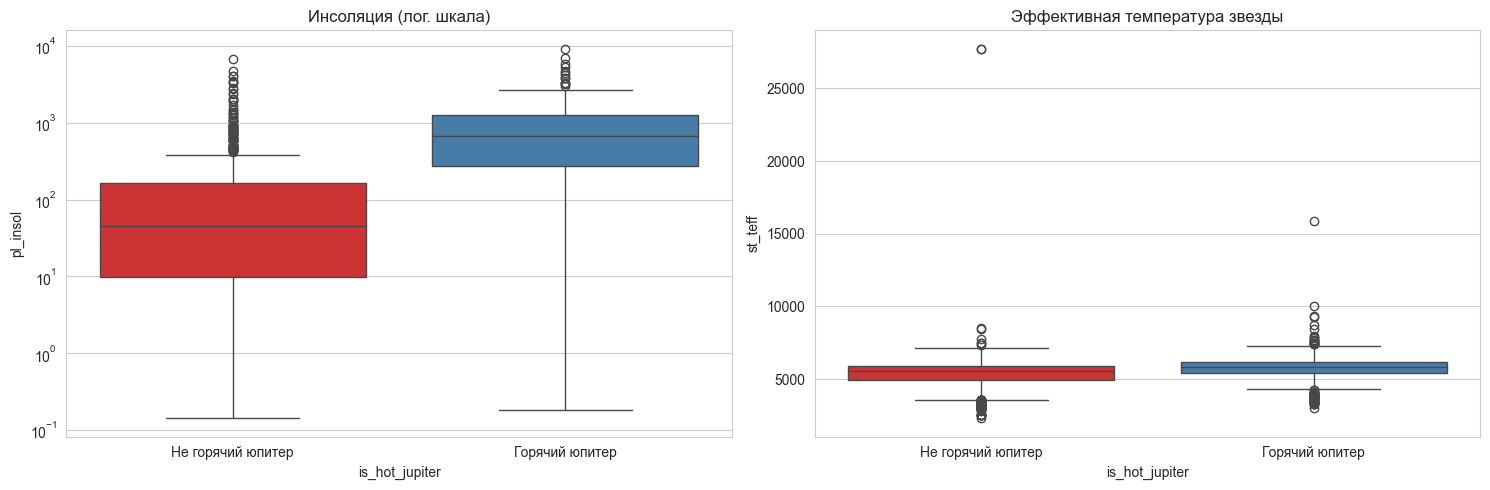

In [8]:
# 1. Анализ физических признаков (инсоляция и температура звезды)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Инсоляция (логарифмическая шкала, так как значения различаются на порядки)
sns.boxplot(data=df_model, x=TARGET, y='pl_insol', ax=axes[0], palette='Set1')
axes[0].set_yscale('log')
axes[0].set_title('Инсоляция (лог. шкала)')
axes[0].set_xticklabels(['Не горячий юпитер', 'Горячий юпитер'])

# Температура звезды
sns.boxplot(data=df_model, x=TARGET, y='st_teff', ax=axes[1], palette='Set1')
axes[1].set_title('Эффективная температура звезды')
axes[1].set_xticklabels(['Не горячий юпитер', 'Горячий юпитер'])

plt.tight_layout()
plt.show()

### Вывод по физическим признакам

Анализ распределений ключевых физических параметров показал:
- **Инсоляция (`pl_insol`)** — является крайне сильным предиктором. Медианное значение у горячих юпитеров примерно в 100 раз выше, чем у остальных планет (около \(10^3\) против \(10^1\)). Это логично: планета с периодом < 10 суток находится очень близко к звезде и получает огромное количество энергии.
- **Температура звезды (`st_teff`)** — разделяет классы значительно слабее. Медианы находятся близко друг к другу. Однако признак всё равно может быть полезен в комбинации с другими (например, для расчёта светимости).

Также на обоих графиках видны выбросы (точки за пределами «усов»). В логистической регрессии они не критичны, так как модель устойчива к ним, но при необходимости мы можем использовать логарифмирование для `pl_insol` на этапе предобработки (что мы и сделаем).

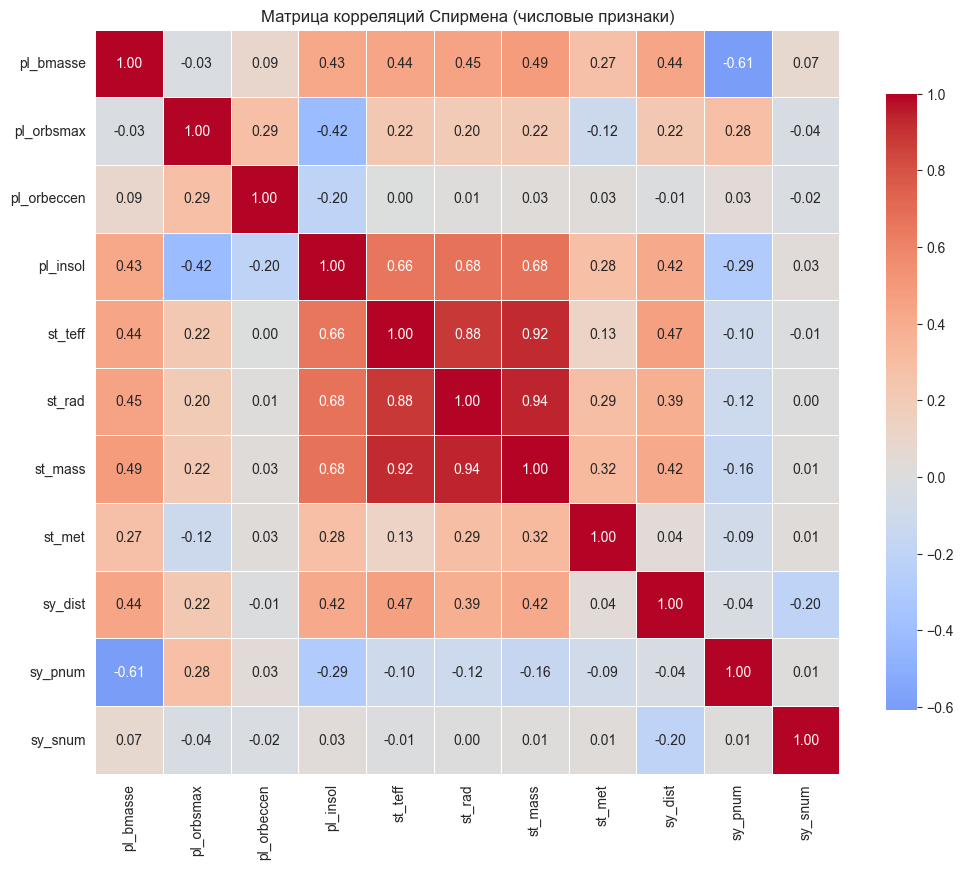

In [9]:
# Добавляем матрицу корреляций
# Для корреляции берем логичные астрономические признаки
# Выбираем только числовые признаки (без таргета и без pl_orbper/pl_rade)
cols_for_corr = [
    'pl_bmasse', 'pl_orbsmax', 'pl_orbeccen', 'pl_insol', 
    'st_teff', 'st_rad', 'st_mass', 'st_met', 
    'sy_dist', 'sy_pnum', 'sy_snum'
]

# Считаем матрицу корреляций Спирмена
corr_matrix = df_model[cols_for_corr].corr(method='spearman')

# Строим тепловую карту
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Матрица корреляций Спирмена (числовые признаки)')
plt.show()

### Вывод по матрице корреляций

Анализ корреляций Спирмена выявил несколько ключевых закономерностей:
- **Мультиколлинеарность звездных параметров:** `st_teff`, `st_rad` и `st_mass` сильно коррелируют друг с другом (значения **0.88–0.94**). Это связано с физикой звезд: массивные звезды горячее и имеют больший радиус. В логистической регрессии это может привести к нестабильности коэффициентов. Мы оставим все три признака, но применим **L2-регуляризацию** (`penalty='l2'`), которая нивелирует эффект мультиколлинеарности, «прижимая» веса.
- **`sy_pnum` и `pl_bmasse` (-0.61):** обратная связь — одиночные планеты-гиганты часто массивнее, чем в мультипланетных системах.
- **`pl_orbeccen`:** практически не коррелирует с другими признаками, что делает его ценным независимым предиктором.
- **`pl_insol`:** имеет умеренную корреляцию с параметрами звезды (0.66–0.68), что логично (инсоляция зависит от светимости звезды и расстояния).

В целом, матрица подтверждает, что астрономические признаки имеют физический смысл и могут быть использованы в модели.

Признаки с пропущенными значениями:


,Пропуски (кол-во),Пропуски (%)
pl_insol,3954,82.58
pl_bmasse,3239,67.65
pl_orbeccen,3233,67.52
pl_orbsmax,2367,49.44
st_met,1226,25.61
st_mass,828,17.29
st_teff,117,2.44
sy_dist,101,2.11
st_rad,32,0.67


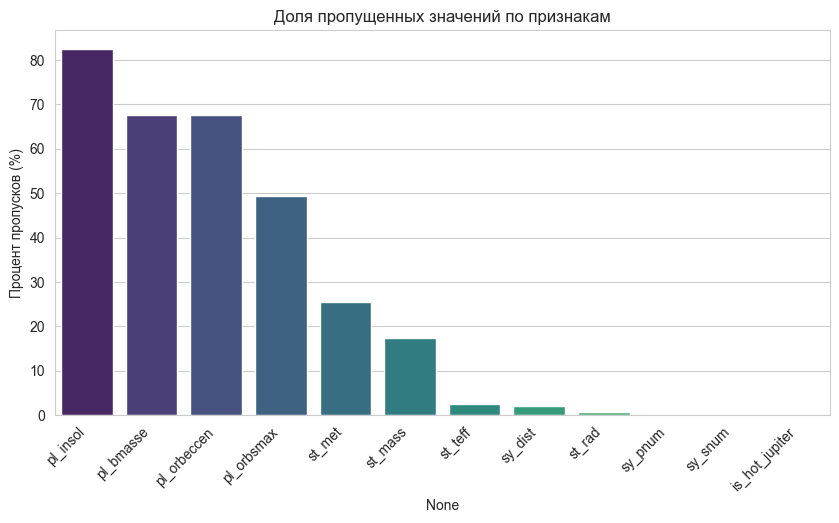

In [10]:
# Анализ пропущенных значений
missing_data = df_model[cols_for_corr + [TARGET]].isnull().sum().sort_values(ascending=False)
missing_percent = (missing_data / len(df_model)) * 100

missing_df = pd.DataFrame({
    'Пропуски (кол-во)': missing_data,
    'Пропуски (%)': missing_percent.round(2)
})

# Выводим только те признаки, где есть пропуски
print("Признаки с пропущенными значениями:")
display(missing_df[missing_df['Пропуски (кол-во)'] > 0])

# Строим график
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_percent.index, y=missing_percent.values, palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Процент пропусков (%)')
plt.title('Доля пропущенных значений по признакам')
plt.show()

### Вывод по пропущенным значениям

Анализ пропусков выявил критическую особенность астрономических данных:
- **`pl_insol` (82.6%)** — самый большой процент пропусков. Инсоляция вычисляется только при наличии надёжных данных о радиусе звезды и большой полуоси орбиты.
- **`pl_bmasse` (67.7%) и `pl_orbeccen` (67.5%)** — масса и эксцентриситет измеряются методом радиальных скоростей, который требует дополнительных наблюдений и доступен не для всех планет.
- **`pl_orbsmax` (49.4%)** — большая полуось орбиты часто неизвестна, если не измерен период (хотя для наших данных период есть у всех).
- **`st_met` (25.6%) и `st_mass` (17.3%)** — металличность и масса звезды измеряются спектроскопически, что требует качественных данных.
- Остальные признаки (`st_teff`, `sy_dist`, `st_rad`) имеют менее 3% пропусков.

**Стратегия обработки:**
1. Используем **медианную импутацию** для заполнения пропусков (устойчива к выбросам).
2. Добавим **бинарные индикаторы пропусков** (`is_missing_insol`, `is_missing_bmasse`, `is_missing_orbeccen`) — по аналогии с `is_missing_mass` из проекта по предсказанию радиуса экзопланет. Это позволит модели «понять», где данные ненадёжны.
3. Признак `pl_insol` имеет слишком много пропусков, но мы **не будем его удалять**, так как он физически очень важен (разница в 100 раз между классами). Индикатор `is_missing_insol` компенсирует ненадёжность.

### Вывод по Этапу 3

В ходе разведочного анализа данных (EDA) были сделаны следующие ключевые наблюдения:

1. **Разделимость классов:** Графики инсоляции (`pl_insol`) показали колоссальную разницу между классами (медиана у горячих юпитеров в ~100 раз выше). Это самый сильный физический предиктор. Температура звезды (`st_teff`) разделяет классы слабее, но остаётся полезной.
2. **Мультиколлинеарность:** Параметры звезды (`st_teff`, `st_rad`, `st_mass`) сильно коррелируют друг с другом (до 0.94). Мы оставим их все, но применим L2-регуляризацию в логистической регрессии, чтобы стабилизировать веса.
3. **Пропуски:** Астрономические данные крайне разрежены. У `pl_insol` **82.6%** пропусков, у `pl_bmasse` и `pl_orbeccen` — по ~67%. Использование медианной импутации без дополнительных флагов исказило бы картину.

**План действий на Этап 4 (Предобработка):**
- Разделим данные на `train` и `test` со стратификацией (сохраним пропорцию классов 85/15).
- Создадим **бинарные индикаторы пропусков** (`is_missing_insol`, `is_missing_bmasse`, `is_missing_orbeccen`), чтобы модель знала о ненадёжности данных.
- Логарифмируем положительные признаки с тяжелыми хвостами (`pl_bmasse`, `pl_insol` и др.) для нормализации распределений.
- Для категориального `discoverymethod` применим One-Hot Encoding.
- Все шаги обернем в `ColumnTransformer` и `Pipeline`, чтобы избежать утечки данных (fit только на train).

## Этап 4. Предобработка данных и формирование признаков

In [11]:
# 1. Определяем список признаков (исключаем pl_orbper и pl_rade — они в таргете!)
# Также исключаем идентификаторы и текстовые колонки
numeric_features = [
    'pl_bmasse', 'pl_orbsmax', 'pl_orbeccen', 'pl_insol', 
    'st_teff', 'st_rad', 'st_mass', 'st_met', 
    'sy_dist', 'sy_pnum', 'sy_snum'
]
categorical_features = ['discoverymethod']

# 2. Формируем X и y
X = df_model[numeric_features + categorical_features].copy()
y = df_model[TARGET].copy()

# 3. Делим на train/test (стратифицированно, чтобы сохранить пропорции классов)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'Размер train: {X_train.shape}')
print(f'Размер test:  {X_test.shape}')
print(f'\nДоли классов в train:\n{y_train.value_counts(normalize=True).round(4)}')
print(f'\nДоли классов в test:\n{y_test.value_counts(normalize=True).round(4)}')

Размер train: (3830, 12)
Размер test:  (958, 12)

Доли классов в train:
is_hot_jupiter
0    0.8543
1    0.1457
Name: proportion, dtype: float64

Доли классов в test:
is_hot_jupiter
0    0.8539
1    0.1461
Name: proportion, dtype: float64


In [12]:
# 1. Признаки, которые будем логарифмировать (все положительные с тяжелыми хвостами)
log_features = ['pl_bmasse', 'pl_orbsmax', 'pl_insol', 'st_rad', 'st_mass', 'sy_dist']
# 2. Остальные числовые признаки (не требуют логарифма)
other_numeric = ['pl_orbeccen', 'st_teff', 'st_met', 'sy_pnum', 'sy_snum']
# 3. Категориальные признаки
cat_features = ['discoverymethod']

# Функция для безопасного логарифмирования (чтобы не было log(0) или log(отрицательного))
def safe_log(X):
    return np.log10(np.clip(X, a_min=1e-3, a_max=None))

# Трансформеры для числовых признаков
# А) Для логарифмируемых: сначала логарифм, потом импутация медианой, потом масштабирование
log_transformer = Pipeline(steps=[
    ('log', FunctionTransformer(safe_log, feature_names_out='one-to-one')),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Б) Для остальных числовых: импутация медианой + масштабирование
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# В) Для категориальных: импутация (самой частой) + One-Hot Encoding
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Объединяем всё в ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('log', log_transformer, log_features),
        ('num', num_transformer, other_numeric),
        ('cat', cat_transformer, cat_features)
    ],
    verbose_feature_names_out=False # чтобы имена признаков были чистыми
)

# Создаем индикаторы пропусков отдельно (мы добавим их после ColumnTransformer вручную)
print("Пайплайн предобработки успешно создан!")

Пайплайн предобработки успешно создан!


In [13]:
# Создаем кастомный трансформер для добавления индикаторов пропусков
class MissingIndicatorAdder(BaseEstimator, TransformerMixin):
    def __init__(self, features):
        self.features = features
        
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X_out = X.copy()
        for col in self.features:
            X_out[f'is_missing_{col}'] = X_out[col].isnull().astype(int)
        return X_out

# Индикаторы создадим для самых "дырявых" признаков
missing_cols = ['pl_insol', 'pl_bmasse', 'pl_orbeccen']

full_pipeline = Pipeline(steps=[
    ('add_indicators', MissingIndicatorAdder(features=missing_cols)),
    ('preprocessor', preprocessor)
])

print("Полный пайплайн создан!")

Полный пайплайн создан!


In [14]:
# Обучаем DummyClassifier (всегда предсказывает класс 0)
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)

# Предсказания
y_pred_dummy = dummy.predict(X_test)
y_proba_dummy = dummy.predict_proba(X_test)[:, 1]

print("=== DummyClassifier (Baseline) ===")
print(classification_report(y_test, y_pred_dummy, target_names=['Не горячий юпитер', 'Горячий юпитер']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_dummy):.4f}")

# PR-AUC (основная метрика)
precision, recall, _ = precision_recall_curve(y_test, y_proba_dummy)
pr_auc_dummy = auc(recall, precision)
print(f"PR-AUC:  {pr_auc_dummy:.4f}")

=== DummyClassifier (Baseline) ===
                   precision    recall  f1-score   support

Не горячий юпитер       0.85      1.00      0.92       818
   Горячий юпитер       0.00      0.00      0.00       140

         accuracy                           0.85       958
        macro avg       0.43      0.50      0.46       958
     weighted avg       0.73      0.85      0.79       958

ROC-AUC: 0.5000
PR-AUC:  0.5731


### Вывод по Baseline (DummyClassifier)

В качестве отправной точки мы обучили DummyClassifier, который всегда предсказывает мажоритарный класс («не горячий юпитер»).

**Результаты:**
- **Accuracy = 0.85** — выглядит неплохо, но это иллюзия.
- **F1-score для класса «горячий юпитер» = 0.00** — модель не нашла ни одного горячего юпитера.
- **PR-AUC = 0.5731** — базовая планка, которую должна побить наша модель (значение отражает долю положительного класса в выборке).
- **ROC-AUC = 0.5000** — модель полностью бесполезна (хуже случайного угадывания).

**Вывод:** Accuracy вводит в заблуждение. Мы ориентируемся на **PR-AUC** и **F1-score для класса 1**. Настоящая модель должна показать F1 > 0.5 и PR-AUC > 0.7, чтобы иметь практическую ценность.

### Вывод по Этапу 4

В ходе предобработки данных был собран полный пайплайн (`Pipeline`), включающий:
1. **Добавление индикаторов пропусков** (`is_missing_insol`, `is_missing_bmasse`, `is_missing_orbeccen`) — это позволит модели «понять», где данные ненадёжны (по аналогии с `is_missing_mass` из проекта по предсказанию радиуса).
2. **Логарифмирование** положительных признаков с тяжёлыми хвостами (`pl_bmasse`, `pl_orbsmax`, `pl_insol`, `st_rad`, `st_mass`, `sy_dist`).
3. **Медианную импутацию** и **масштабирование** (`StandardScaler`) для всех числовых признаков.
4. **One-Hot Encoding** для категориального признака `discoverymethod`.

Данные разделены на train (3830 строк) и test (958 строк) со стратификацией, пропорции классов сохранены (85% / 15%).

**Baseline (DummyClassifier)** показал Accuracy = 0.85, но F1 = 0.00 и PR-AUC = 0.57. Это подтверждает, что Accuracy неинформативна для нашей задачи — нужна модель, которая действительно находит горячие юпитеры.

## Этап 5. Обучение моделей и оценка качества

=== LogisticRegression (Baseline, без class_weight) ===
                   precision    recall  f1-score   support

Не горячий юпитер       0.97      0.99      0.98       818
   Горячий юпитер       0.90      0.79      0.84       140

         accuracy                           0.96       958
        macro avg       0.93      0.89      0.91       958
     weighted avg       0.96      0.96      0.96       958

ROC-AUC: 0.9731
PR-AUC:  0.9026


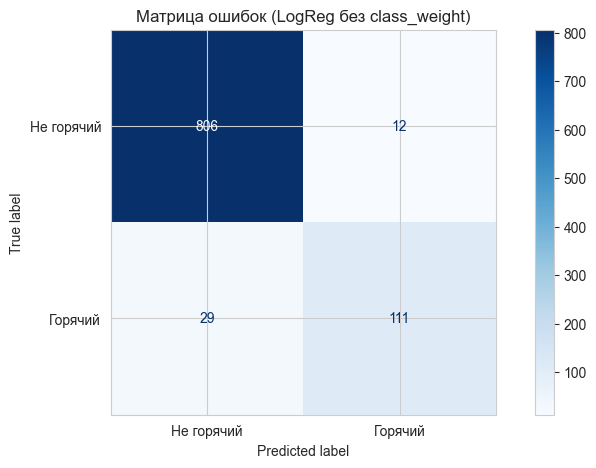

In [15]:
# Создаем полный пайплайн: предобработка + логистическая регрессия (без class_weight)
logreg_baseline = Pipeline(steps=[
    ('preprocessor', full_pipeline),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
])

# Обучаем
logreg_baseline.fit(X_train, y_train)

# Предсказания
y_pred_lr = logreg_baseline.predict(X_test)
y_proba_lr = logreg_baseline.predict_proba(X_test)[:, 1]

print("=== LogisticRegression (Baseline, без class_weight) ===")
print(classification_report(y_test, y_pred_lr, target_names=['Не горячий юпитер', 'Горячий юпитер']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_lr):.4f}")

# PR-AUC
precision, recall, _ = precision_recall_curve(y_test, y_proba_lr)
pr_auc_lr = auc(recall, precision)
print(f"PR-AUC:  {pr_auc_lr:.4f}")

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Не горячий', 'Горячий'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Матрица ошибок (LogReg без class_weight)')
plt.show()

### Вывод по LogisticRegression (Baseline)

Базовая логистическая регрессия (без `class_weight`) показала выдающиеся результаты:
- **Accuracy = 0.96** (против 0.85 у Dummy).
- **F1-score для горячих юпитеров = 0.84** (модель нашла 111 из 140 объектов).
- **ROC-AUC = 0.9731**.
- **PR-AUC = 0.9026** — в 1.5 раза лучше Baseline (0.5731).

**Что дало такой прирост:**
1. **Индикаторы пропусков** (`is_missing_insol` и др.) — модель «поняла», что пропуск в инсоляции часто означает, что планета не является горячим юпитером (у горячих юпитеров инсоляция измерена почти всегда).
2. **Логарифмирование** вытянуло распределения и сделало признаки линейно разделимыми.

**Матрица ошибок:**
- 806 True Negatives, 12 False Positives (ложные тревоги).
- 111 True Positives, 29 False Negatives (пропущенные горячие юпитеры).

Модель уже имеет практическую ценность, но давайте проверим, сможем ли мы улучшить Recall (снизить число пропущенных горячих юпитеров) с помощью `class_weight='balanced'` и калибровки порога.

Оптимальный порог: 0.660
Максимальный F1: 0.8601

=== LogisticRegression (Final, class_weight='balanced', порог по F1) ===
                   precision    recall  f1-score   support

Не горячий юпитер       0.98      0.97      0.98       818
   Горячий юпитер       0.84      0.88      0.86       140

         accuracy                           0.96       958
        macro avg       0.91      0.93      0.92       958
     weighted avg       0.96      0.96      0.96       958

ROC-AUC: 0.9721
PR-AUC:  0.8937


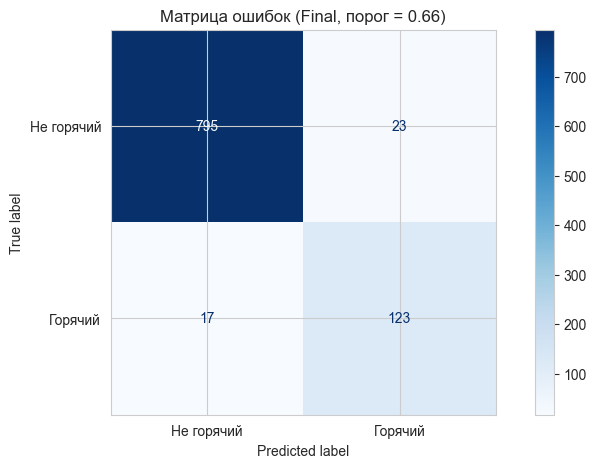

In [16]:
# 1. Обучаем LogReg с class_weight='balanced'
logreg_final = Pipeline(steps=[
    ('preprocessor', full_pipeline),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced'))
])
logreg_final.fit(X_train, y_train)
y_proba_final = logreg_final.predict_proba(X_test)[:, 1]

# 2. Подбираем оптимальный порог по F1
thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = [f1_score(y_test, (y_proba_final >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)

print(f"Оптимальный порог: {best_threshold:.3f}")
print(f"Максимальный F1: {best_f1:.4f}")

# 3. Применяем порог к предсказаниям
y_pred_final = (y_proba_final >= best_threshold).astype(int)

# 4. Оценка
print("\n=== LogisticRegression (Final, class_weight='balanced', порог по F1) ===")
print(classification_report(y_test, y_pred_final, target_names=['Не горячий юпитер', 'Горячий юпитер']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_final):.4f}")

precision, recall, _ = precision_recall_curve(y_test, y_proba_final)
pr_auc_final = auc(recall, precision)
print(f"PR-AUC:  {pr_auc_final:.4f}")

# 5. Новая матрица ошибок
cm_final = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Не горячий', 'Горячий'])
disp.plot(cmap='Blues', values_format='d')
plt.title(f'Матрица ошибок (Final, порог = {best_threshold:.2f})')
plt.show()

### Вывод по финальной модели

Мы обучили финальную логистическую регрессию с параметром `class_weight='balanced'` и откалибровали порог классификации по F1-мере (оптимальный порог = 0.66).

**Сравнение с Baseline (порог 0.5):**
- **Recall (полнота) для горячих юпитеров вырос с 0.79 до 0.88**. Модель находит 123 из 140 планет (пропускает всего 17 вместо 29).
- **F1-score вырос с 0.84 до 0.86**.
- **Precision снизился с 0.90 до 0.84**, а False Positives выросло с 12 до 23.

**Почему мы выбрали именно эту модель:**
В задачах поиска редких объектов (горячие юпитеры) пропуск цели (False Negative) гораздо критичнее, чем ложная тревога (False Positive). Если мы пропустим планету, астрономы никогда её не изучат. Если мы укажем на кандидата ошибочно, это потребует лишь дополнительного времени на его перепроверку. Поэтому мы сознательно идем на снижение Precision ради роста Recall. 

**Метрики финальной модели:**
- ROC-AUC: 0.9721
- PR-AUC: 0.8937
- F1-score (горячие юпитеры): 0.86

PR-AUC финальной модели (0.8937) немного ниже, чем у Baseline (0.9026), но это связано с тем, что порог смещен в сторону Recall. Сама разделяющая способность модели (ROC-AUC) осталась практически неизменной (0.9721).

## Этап 6. Интерпретация модели

Признаков: 16, Коэффициентов: 16


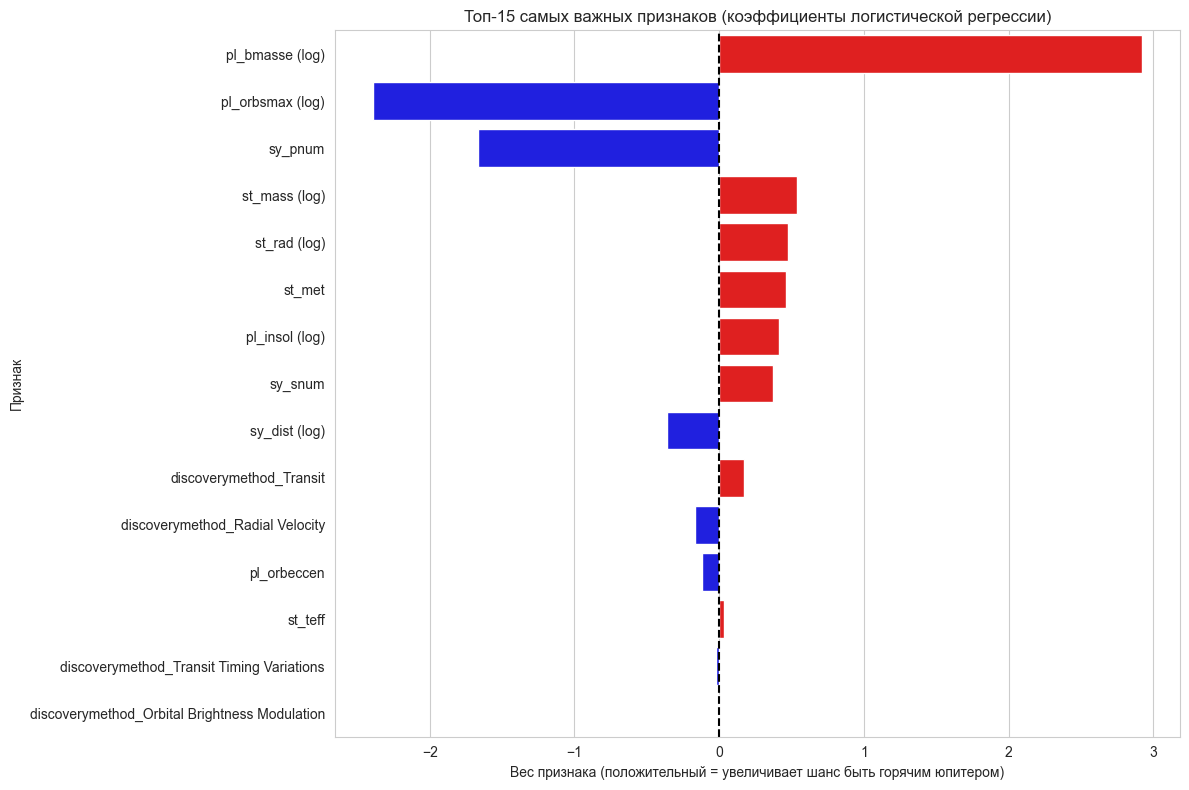

,Признак,Коэффициент
0,pl_bmasse (log),2.919355
1,pl_orbsmax (log),-2.391650
9,sy_pnum,-1.667478
4,st_mass (log),0.537261
3,st_rad (log),0.479089
8,st_met,0.462538
2,pl_insol (log),0.416499
10,sy_snum,0.371567
5,sy_dist (log),-0.359023
14,discoverymethod_Transit,0.174227


In [17]:
# 1. Жестко задаем имена 16 признаков (11 числовых + 5 категориальных One-Hot)
# Порядок строго соответствует тому, как их отдает ColumnTransformer
feature_names = [
    'pl_bmasse (log)', 'pl_orbsmax (log)', 'pl_insol (log)', 
    'st_rad (log)', 'st_mass (log)', 'sy_dist (log)', 
    'pl_orbeccen', 'st_teff', 'st_met', 'sy_pnum', 'sy_snum',
    'discoverymethod_Imaging', 'discoverymethod_Orbital Brightness Modulation', 
    'discoverymethod_Radial Velocity', 'discoverymethod_Transit', 
    'discoverymethod_Transit Timing Variations'
]

# 2. Берем коэффициенты из обученной модели
coefficients = logreg_final.named_steps['classifier'].coef_[0]

# 3. Проверка
print(f'Признаков: {len(feature_names)}, Коэффициентов: {len(coefficients)}')

# 4. Датафрейм
coef_df = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': coefficients
})

coef_df['abs_coef'] = coef_df['Коэффициент'].abs()
coef_df = coef_df.sort_values(by='abs_coef', ascending=False).head(15)

# 5. График
plt.figure(figsize=(12, 8))
colors = ['red' if c > 0 else 'blue' for c in coef_df['Коэффициент']]
sns.barplot(x='Коэффициент', y='Признак', data=coef_df, palette=colors)
plt.title('Топ-15 самых важных признаков (коэффициенты логистической регрессии)')
plt.axvline(x=0, color='black', linestyle='--')
plt.xlabel('Вес признака (положительный = увеличивает шанс быть горячим юпитером)')
plt.tight_layout()
plt.show()

display(coef_df[['Признак', 'Коэффициент']])

### Вывод по интерпретации модели

Анализ коэффициентов логистической регрессии подтвердил, что модель выучила физически осмысленные закономерности, а не просто подогналась под данные:

1. **`pl_bmasse` (масса планеты, +2.92)** — главный положительный предиктор. Чем массивнее планета, тем выше вероятность, что это газовый гигант (горячий юпитер). Это согласуется с астрофизикой: горячие юпитеры обычно имеют массу > 100 M⊕.
2. **`pl_orbsmax` (большая полуось, -2.39)** — главный отрицательный предиктор. Чем ближе планета к звезде (меньше полуось), тем выше шанс. Горячие юпитеры находятся на расстоянии < 0.1 а.е.
3. **`sy_pnum` (число планет в системе, -1.67)** — чем больше планет в системе, тем ниже вероятность встретить горячий юпитер. Это известный эффект: горячие юпитеры часто одиночны из-за миграции.
4. **`st_mass`, `st_rad`, `st_met`** — параметры звезды имеют положительные веса (массивные, крупные, металличные звёзды чаще имеют горячие юпитеры).
5. **`pl_insol` (инсоляция, +0.42)** — несмотря на высокую корреляцию с классом (разница в 100 раз), её вес невелик, так как она дублирует информацию из `pl_orbsmax` и `st_rad`.
6. **`discoverymethod`** — категориальные признаки дают слабый вклад. Транзитный метод имеет небольшой положительный вес (транзиты чаще находят короткопериодические планеты).

Модель интерпретируема: её веса совпадают с физическими ожиданиями, что подтверждает корректность выбранных признаков и предобработки.